# Notebook 01 — Computing the Al–Zn binary phase diagram with pycalphad

**Goal:** go from a thermodynamic database file (`.tdb`) to a full binary phase diagram, and understand every step along the way.

**What you will learn**

1. What is inside a CALPHAD thermodynamic database (TDB) file.
2. How to ask pycalphad "what phases are stable at this temperature and composition?" (a single *equilibrium* calculation).
3. How pycalphad repeats that calculation over a grid of temperatures/compositions to draw a *phase diagram*.
4. How to read the important features of the Al–Zn diagram (eutectic, miscibility gap, monotectoid) that matter for solidification in Notebook 02.

> **Prerequisites:** none beyond basic Python. If a word like *Gibbs energy* or *phase* is new, read the [project README](../README.md) first — it explains what CALPHAD is.

---

### 📚 Database used (please cite it if you reuse these results)

| | |
|---|---|
| **File** | `databases/alzn_mey.tdb` |
| **Thermodynamic assessment** | S. an Mey, *"Reevaluation of the Al–Zn system"*, **Z. Metallkd. 84 (1993) 451–455**. |
| **TDB file prepared by** | T. Abe, K. Hashimoto, Y. Sawada, National Institute for Materials Science (NIMS), Japan — Computational Phase Diagram Database (CPDDB), © NIMS 2009 (file dated 2011‑11‑09). |
| **Where we got it** | The open example databases shipped with pycalphad: [`pycalphad/pycalphad` → `examples/databases/alzn_mey.tdb`](https://github.com/pycalphad/pycalphad/blob/develop/examples/databases/alzn_mey.tdb) (copied unchanged from commit `0cbc613`). |
| **Software** | R. Otis & Z.-K. Liu, *"pycalphad: CALPHAD-based Computational Thermodynamics in Python"*, **J. Open Res. Softw. 5 (2017) 1**, doi:[10.5334/jors.140](https://doi.org/10.5334/jors.140). |

## 1. Imports

Every notebook starts by importing the libraries it needs. Run each cell with **Shift + Enter**.

In [1]:
# --- Standard scientific-Python tools -------------------------------------
import numpy as np                 # fast arrays & math
import matplotlib.pyplot as plt    # plotting

# --- pycalphad: the CALPHAD engine -----------------------------------------
# Database   : reads a .tdb file into Python
# equilibrium: minimises the Gibbs energy -> tells us the stable phases
# binplot    : maps out a whole binary phase diagram for us
# variables  : the "state variables" (T, P, N, X(...)) we use to set conditions
from pycalphad import Database, equilibrium, binplot
from pycalphad import variables as v

# pycalphad/numpy currently emit harmless DeprecationWarnings with NumPy >= 2.5.
# They don't affect the results, so we hide them to keep the output readable.
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import pycalphad
print("pycalphad version:", pycalphad.__version__)

pycalphad version: 0.11.2


## 2. Load the thermodynamic database

A TDB file is plain text. It contains, for each **phase** (liquid, FCC solid, HCP solid, …), a mathematical model of its **Gibbs energy** *G* as a function of temperature *T* and composition. Those parameters were fitted ("assessed") by the database author to experimental data: measured phase boundaries, heats of mixing, activities, etc.

Once we have *G* for every phase, finding the stable state is "just" a minimisation problem: **nature picks the combination of phases with the lowest total Gibbs energy.** That is exactly what pycalphad does.

Feel free to open `databases/alzn_mey.tdb` in a text editor — lines starting with `PHASE`, `CONSTITUENT` and `PARAMETER G(...)` are the interesting ones.

In [2]:
# Path is relative to this notebook (which lives in the notebooks/ folder)
DB_PATH = "../databases/alzn_mey.tdb"

db = Database(DB_PATH)

# What elements and phases does the database know about?
print("Elements:", sorted(db.elements))
print("Phases  :", sorted(db.phases.keys()))

Elements: ['/-', 'AL', 'VA', 'ZN']
Phases  : ['FCC_A1', 'HCP_A3', 'LIQUID']


**What these names mean**

| Name in TDB | Meaning | In Al–Zn |
|---|---|---|
| `LIQUID` | the melt | Al and Zn are fully miscible as liquids |
| `FCC_A1` | face-centred cubic solid solution | this is "(Al)", aluminium with dissolved Zn |
| `HCP_A3` | hexagonal close-packed solid solution | this is "(Zn)", zinc with a little dissolved Al |
| `VA` | *vacancy* | a bookkeeping "element" used by the sublattice models — always include it in the component list |
| `/-` | electron | only used for ionic/charged models; ignore it here |

In [3]:
# The COMPONENTS we want in our calculation. Always add 'VA' (vacancies).
COMPONENTS = ["AL", "ZN", "VA"]

# Use every phase in the database. (For bigger databases you would normally
# pick only the phases relevant to your system.)
PHASES = list(db.phases.keys())
PHASES

['LIQUID', 'FCC_A1', 'HCP_A3']

## 3. One single equilibrium calculation (the building block)

Before drawing a whole diagram, let's ask one concrete question:

> *"An alloy with 30 at.% Zn is held at 780 K (507 °C). Which phases are present, how much of each, and what are their compositions?"*

**Conditions** in pycalphad are a Python dictionary of *state variables*:

* `v.T` – temperature in **kelvin**
* `v.P` – pressure in **pascal** (101325 Pa = 1 atm)
* `v.N` – total number of moles (1 is fine — results are per mole of atoms)
* `v.X('ZN')` – **mole fraction** of Zn (*not* weight percent! see the conversion helper below)

For a binary we only specify the mole fraction of *one* element; Al is whatever is left over (1 − X<sub>Zn</sub>).

In [4]:
conditions = {
    v.T: 780,          # K
    v.P: 101325,       # Pa
    v.N: 1,            # mol of atoms
    v.X("ZN"): 0.30,   # mole fraction Zn (0.30 = 30 at.%)
}

eq = equilibrium(db, COMPONENTS, PHASES, conditions)

# 'eq' is an xarray Dataset: a labelled multi-dimensional array.
# The three things you'll use most:
#   eq.Phase : names of the phases present
#   eq.NP    : "number of moles of phase" = phase fraction
#   eq.X     : composition of each phase
# .squeeze() just drops the length-1 dimensions (we only gave one T, one X, ...)
phase_names = eq.Phase.squeeze().values
phase_frac  = eq.NP.squeeze().values
x_zn_phase  = eq.X.sel(component="ZN").squeeze().values

for name, frac, xzn in zip(phase_names, phase_frac, x_zn_phase):
    if name == "":         # empty slots are just padding -> skip them
        continue
    print(f"{name:8s}  phase fraction = {frac:5.3f}   X(Zn) in this phase = {xzn:5.3f}")

FCC_A1    phase fraction = 0.709   X(Zn) in this phase = 0.204
LIQUID    phase fraction = 0.291   X(Zn) in this phase = 0.533


**Interpretation:** at 780 K this alloy is *in the two-phase region* — part liquid, part FCC solid. Notice:

* The **liquid is richer in Zn** than the overall alloy, and the **FCC solid is poorer in Zn**. Zn is "rejected" by the growing solid into the liquid. This *partitioning* is the root cause of the microsegregation we study in Notebook 02.
* The phase fractions obey the **lever rule**: you can check that `f_liq·X_liq + f_fcc·X_fcc = 0.30`.

Let's verify that last claim numerically — good habit for building trust in a tool:

In [5]:
mask = phase_names != ""
overall_x = np.sum(phase_frac[mask] * x_zn_phase[mask])
print(f"Mass balance check: sum(f_i * X_i) = {overall_x:.4f}  (should equal 0.30)")

Mass balance check: sum(f_i * X_i) = 0.3000  (should equal 0.30)


## 4. Weight percent ↔ mole fraction helper

Lab alloys are almost always specified in **weight percent (wt.%)**, while CALPHAD works in **mole fraction**. Because Zn atoms are ~2.4× heavier than Al atoms, the difference is large (e.g. 30 wt.% Zn ≈ 15 at.% Zn). We define two small helper functions and use them throughout.

In [6]:
# Atomic masses (g/mol) — from IUPAC standard atomic weights
M_AL = 26.9815
M_ZN = 65.38

def wt_to_x_zn(wt_pct_zn):
    # Convert wt.% Zn -> mole fraction Zn (works on numbers or numpy arrays).
    w = np.asarray(wt_pct_zn) / 100.0
    n_zn = w / M_ZN               # moles of Zn in 1 g of alloy
    n_al = (1.0 - w) / M_AL       # moles of Al in 1 g of alloy
    return n_zn / (n_zn + n_al)

def x_to_wt_zn(x_zn):
    # Convert mole fraction Zn -> wt.% Zn.
    x = np.asarray(x_zn)
    m_zn = x * M_ZN               # grams of Zn in 1 mol of atoms
    m_al = (1.0 - x) * M_AL       # grams of Al in 1 mol of atoms
    return 100.0 * m_zn / (m_zn + m_al)

for wt in [10, 30, 50, 95]:
    print(f"{wt:3d} wt.% Zn  =  X(Zn) = {wt_to_x_zn(wt):.3f}")

 10 wt.% Zn  =  X(Zn) = 0.044
 30 wt.% Zn  =  X(Zn) = 0.150
 50 wt.% Zn  =  X(Zn) = 0.292
 95 wt.% Zn  =  X(Zn) = 0.887


## 5. The full phase diagram

A binary phase diagram is just thousands of equilibrium calculations like the one above, on a grid of (X<sub>Zn</sub>, T), with lines drawn where the set of stable phases changes. `binplot` does the bookkeeping for us.

* `v.X('ZN'): (0, 1, 0.02)` → scan compositions from 0 to 1 in steps of 0.02
* `v.T: (300, 1000, 10)` → scan temperatures from 300 K to 1000 K in steps of 10 K

pycalphad's mapping algorithm then *traces* the phase boundaries precisely between grid points, so the step sizes mostly control how many tie-lines are drawn, not the boundary accuracy. Expect this cell to take a few seconds.

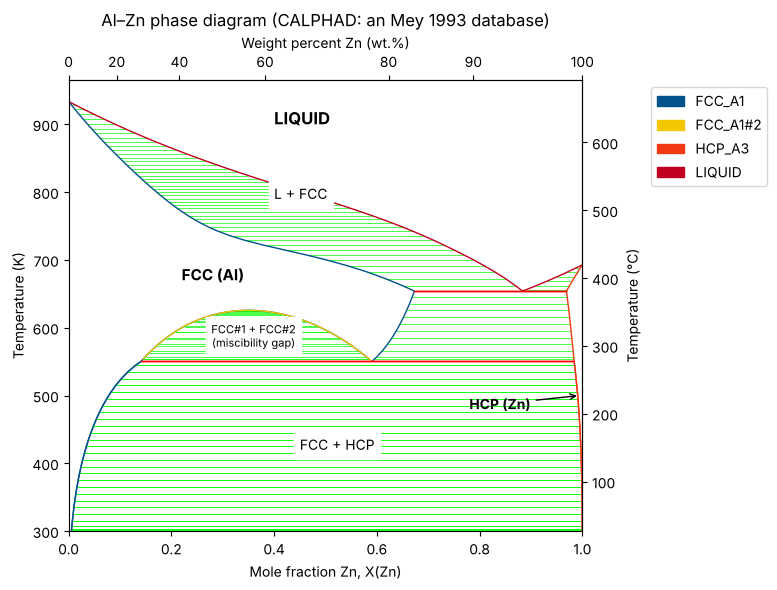

In [7]:
# Create an empty figure and axes, then hand the axes to binplot to draw on.
fig, ax = plt.subplots(figsize=(8, 6))

binplot(
    db, COMPONENTS, PHASES,
    {v.N: 1, v.P: 101325,
     v.T: (300, 1000, 10),       # (start, stop, step) in K
     v.X("ZN"): (0, 1, 0.02)},   # (start, stop, step) in mole fraction
    plot_kwargs={"ax": ax},
)

# --- Make the diagram friendlier for lab use -------------------------------
ax.set_title("Al–Zn phase diagram (CALPHAD: an Mey 1993 database)")
ax.set_xlabel("Mole fraction Zn, X(Zn)")
ax.set_ylabel("Temperature (K)")

# Secondary axes: wt.% on top, °C on the right, so you can read lab units.
top = ax.secondary_xaxis("top", functions=(x_to_wt_zn, wt_to_x_zn))
top.set_xlabel("Weight percent Zn (wt.%)")
top.set_xticks([0, 20, 40, 60, 80, 90, 100])
right = ax.secondary_yaxis("right", functions=(lambda T: T - 273.15, lambda C: C + 273.15))
right.set_ylabel("Temperature (°C)")

# Move the legend outside so it doesn't hide the °C axis
leg = ax.get_legend()          # binplot already made a legend; just reposition it
leg.set_loc("upper left")
leg.set_bbox_to_anchor((1.12, 1.0))

# Label the single-phase fields so beginners know what they are looking at
ax.text(0.40, 900, "LIQUID", fontsize=12, weight="bold")
ax.text(0.22, 670, "FCC (Al)", fontsize=11, weight="bold")
ax.text(0.40, 790, "L + FCC", fontsize=10, backgroundcolor="white")
ax.text(0.45, 420, "FCC + HCP", fontsize=10, backgroundcolor="white")
ax.text(0.36, 572, "FCC#1 + FCC#2\n(miscibility gap)", fontsize=8, ha="center", backgroundcolor="white")
ax.annotate("HCP (Zn)", xy=(0.995, 500), xytext=(0.78, 480), fontsize=10,
            weight="bold", arrowprops={"arrowstyle": "->"})

fig.tight_layout()
import os
os.makedirs("../figures", exist_ok=True)
fig.savefig("../figures/AlZn_phase_diagram.png", dpi=200, bbox_inches="tight")
plt.show()

### How to read this diagram

**Lines** are phase boundaries; **thin tie-lines** inside a two-phase region connect the two phase compositions that coexist at that temperature (the green/red horizontal segments). The key features for this project:

| Feature | Approx. location (from the database) | Why it matters |
|---|---|---|
| **Melting point of pure Al** | 933 K (660 °C), left edge | top of the FCC liquidus |
| **Liquidus** (upper curve from Al side) | falls steadily with Zn | temperature at which the first solid forms on cooling |
| **Solidus** (lower curve of the L + FCC field) | well below the liquidus → wide freezing range | the bigger the gap between liquidus and solidus, the more microsegregation |
| **Eutectic** L → FCC + HCP | ≈ 654 K (≈ 381 °C) at X<sub>Zn</sub> ≈ 0.88 (≈ 95 wt.%) | in Scheil solidification, the last liquid always ends up here |
| **FCC miscibility gap** | dome peaking ≈ 625 K | the FCC solid splits into Al-rich and Zn-rich FCC (solid state — does not affect solidification) |
| **Monotectoid** FCC#2 → FCC#1 + HCP | ≈ 550 K (≈ 277 °C) | solid-state reaction, again below the solidification range |

> 💡 **Key observation for Notebook 02:** for Al-rich alloys (left half), the equilibrium solidus is far *above* the eutectic temperature. So *at equilibrium*, an Al–10 wt.% Zn alloy should freeze completely as single-phase FCC without ever reaching the eutectic. We'll see that real (Scheil-like) solidification disagrees!

## 6. Find the eutectic precisely (optional, but a nice exercise)

Rather than reading the eutectic off the plot, we can *compute* it. At the eutectic composition, the liquid survives to the lowest temperature. Below we calculate equilibrium for a fine grid of temperatures at X<sub>Zn</sub> = 0.88 and find the lowest temperature where any liquid is still present.

In [8]:
T_grid = np.arange(650.0, 660.0, 0.05)  # K, fine steps around the eutectic
eq_eut = equilibrium(db, COMPONENTS, PHASES,
                     {v.N: 1, v.P: 101325, v.T: T_grid, v.X("ZN"): 0.88})

# Sum the phase fraction of every slot whose name is LIQUID, at each T
is_liquid = (eq_eut.Phase == "LIQUID")
liquid_frac = eq_eut.NP.where(is_liquid).sum(dim="vertex").squeeze().values

T_eut = T_grid[np.argmax(liquid_frac > 1e-6)]  # first T (from below) with liquid
print(f"Eutectic temperature ≈ {T_eut:.2f} K = {T_eut - 273.15:.1f} °C")
print("(Literature/assessed value: ~381 °C — good agreement.)")

Eutectic temperature ≈ 654.05 K = 380.9 °C
(Literature/assessed value: ~381 °C — good agreement.)


## 7. Things to try on your own

1. **Change the database.** pycalphad's examples folder also contains e.g. `Al-Mg_Zhong.tdb` and `alfe_sei.TDB`. Copy one into `databases/`, change `DB_PATH`, `COMPONENTS` and the axis labels, and re-run.
2. **Zoom in.** Change the temperature range in `binplot` to `(600, 950, 5)` to look only at the solidification region.
3. **Equilibrium at your alloy.** In Section 3, set `v.X('ZN')` to `wt_to_x_zn(<your wt.%>)` and step through temperatures to see when liquid disappears.

➡️ **Next:** [`02_equilibrium_vs_scheil_solidification.ipynb`](02_equilibrium_vs_scheil_solidification.ipynb)